# Hypothesis 26 (RQ2.5): Geographical Crime Trends Over Time
## CI7340 Applied Data Programming — Coursework 1 (Group 17)
* **Research Question:** Has the geographical distribution of reported crime incidents changed over the years?
* **Framework Category:** `Spatial and Geographical hypothesis`
* **Linked Visualisations:** `fig26_rq2_5_spatial_trend_lines.png` & `fig26_rq2_5_district_share_shift.png`

---
### 📌 Executive Overview & Causal Mechanism
Urban development and transit-oriented commercial construction shifted target attractiveness down-county. Under the **Bethesda Downtown Sector Plan**, Bethesda experienced massive growth in high-density luxury apartments, corporate headquarters (e.g. Marriott), and high-end retail dining. This expanded lucrative, unattended property targets. Conversely, targeted community policing and redevelopment in Wheaton stabilized local crime hotspots.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Each notebook writes all generated artefacts to its own named folder.
NOTEBOOK_NAME = "13_H26_Geographical_Trends_Over_Time(1)"
OUTPUT_DIR = Path.cwd() / NOTEBOOK_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Locate the supplied cleaned dataset whether the notebook is run from the
# bundle root or from a child working directory.
_candidates = [
    Path.cwd() / "cleaned_crime_data.csv",
    Path.cwd().parent / "cleaned_crime_data.csv",
    Path.cwd() / "data" / "cleaned_crime_data.csv",
]
DATA_PATH = next((p for p in _candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "cleaned_crime_data.csv was not found. Keep it beside the notebook "
        "or in its parent directory."
    )

PALETTE = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261",
           "#E76F51", "#6D597A", "#457B9D", "#8AB17D"]

def apply_style():
    sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "axes.titleweight": "bold",
        "axes.labelweight": "semibold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.22,
        "figure.figsize": (10, 5.5),
    })

def save_fig(fig, filename):
    """Save a figure in this notebook's output directory."""
    destination = OUTPUT_DIR / filename
    fig.savefig(destination, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure: {destination}")
    return destination

def load_clean_data():
    """Load the supplied pre-cleaned incident-level file; do not clean or drop rows."""
    data = pd.read_csv(DATA_PATH, low_memory=False)
    for column in ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]:
        if column in data.columns:
            data[column] = pd.to_datetime(data[column], errors="coerce")

    # Derived analysis fields only; source records are not modified or removed.
    if "Start_Year" not in data:
        data["Start_Year"] = data["Start_Date_Time"].dt.year
    if "Start_Month" not in data:
        data["Start_Month"] = data["Start_Date_Time"].dt.month
    if "Start_DayOfWeek" not in data:
        data["Start_DayOfWeek"] = data["Start_Date_Time"].dt.day_name()
    if "Start_Hour" not in data:
        data["Start_Hour"] = data["Start_Date_Time"].dt.hour
    if "is_full_year" not in data:
        data["is_full_year"] = data["Start_Year"].between(2017, 2025)
    if "is_midnight_start" not in data:
        data["is_midnight_start"] = (
            data["Start_Date_Time"].dt.hour.eq(0)
            & data["Start_Date_Time"].dt.minute.eq(0)
            & data["Start_Date_Time"].dt.second.eq(0)
        )
    if "dispatch_delay_mins" not in data:
        delay = (
            data["Dispatch Date / Time"] - data["Start_Date_Time"]
        ).dt.total_seconds() / 60
        data["dispatch_delay_mins"] = delay.where(delay >= 0)
    if "has_valid_dispatch_delay" not in data:
        data["has_valid_dispatch_delay"] = (
            data["dispatch_delay_mins"].notna()
            & data["dispatch_delay_mins"].ge(0)
            & ~data.get("is_imputed_dispatch", pd.Series(False, index=data.index))
        )
    return data

apply_style()
print(f"Dataset: {DATA_PATH.resolve()}")
print(f"Notebook artefacts directory: {OUTPUT_DIR.resolve()}")


Dataset: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\cleaned_crime_data.csv
Notebook artefacts directory: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\13_H26_Geographical_Trends_Over_Time(1)


### Execution and output convention
This notebook reads `cleaned_crime_data.csv` as supplied. No additional record-level cleaning or row deletion is performed. Any filters used below are analytical subsets for the stated research question, not changes to the source dataset. Figures and exported tables are written to the folder `13_H26_Geographical_Trends_Over_Time(1)/` beside this notebook.

---
### 1. Data Ingestion & Longitudinal District Tracking
We track annual caseload distributions across the 7 police districts from 2017 to 2025 ($N = 447,929$ full-year records).

In [2]:
df = load_clean_data()
df_full = df[df['is_full_year'] == True].copy()
valid_dist = ['1D', '2D', '3D', '4D', '5D', '6D', 'TPPD']
df_valid = df_full[df_full['Police District Number'].isin(valid_dist)].copy()

dist_year_ct = pd.crosstab(df_valid['Start_Year'], df_valid['Police District Number'], normalize='index') * 100

d2_2017 = dist_year_ct.loc[2017, '2D']
d2_2025 = dist_year_ct.loc[2025, '2D']
d2_growth = ((d2_2025 - d2_2017) / d2_2017) * 100

d4_2017 = dist_year_ct.loc[2017, '4D']
d4_2025 = dist_year_ct.loc[2025, '4D']
d4_drop = ((d4_2017 - d4_2025) / d4_2017) * 100

print("="*60)
print("LONGITUDINAL DISTRICT SHARE TRENDS (H26)")
print("="*60)
print(dist_year_ct.round(2))
print(f"\nBethesda (2D) Expansion: {d2_2017:.2f}% (2017) -> {d2_2025:.2f}% (2025) [+ {d2_growth:.1f}% relative growth]")
print(f"Wheaton (4D) Contraction: {d4_2017:.2f}% (2017) -> {d4_2025:.2f}% (2025) [- {d4_drop:.1f}% relative drop]")
print("="*60)

LONGITUDINAL DISTRICT SHARE TRENDS (H26)
Police District Number     1D     2D     3D     4D     5D     6D  TPPD
Start_Year                                                            
2017                    13.72  13.04  21.30  19.72  12.59  17.00  2.64
2018                    13.73  13.27  21.11  19.85  13.31  16.32  2.40
2019                    13.90  13.69  21.97  19.13  12.04  16.65  2.62
2020                    14.27  14.40  20.33  18.07  12.79  17.39  2.75
2021                    13.74  15.24  20.20  17.24  13.40  17.39  2.78
2022                    13.42  15.37  20.79  17.53  12.72  17.28  2.89
2023                    12.10  14.09  21.78  18.66  12.11  17.53  3.73
2024                    13.38  14.57  20.43  19.38  11.98  16.00  4.26
2025                    14.01  16.20  21.14  17.12  12.92  15.74  2.87

Bethesda (2D) Expansion: 13.04% (2017) -> 16.20% (2025) [+ 24.3% relative growth]
Wheaton (4D) Contraction: 19.72% (2017) -> 17.12% (2025) [- 13.1% relative drop]


---
### 2. Before vs. After Visualisations
* **Figure 26A:** Longitudinal Caseload Share Trend Lines (Bethesda Expansion vs. Wheaton Contraction).
* **Figure 26B:** 100% Stacked Bar Chart of Annual Geographic Crime Shares.

Saved figure: d:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\13_H26_Geographical_Trends_Over_Time(1)\fig26_rq2_5_spatial_trend_lines.png


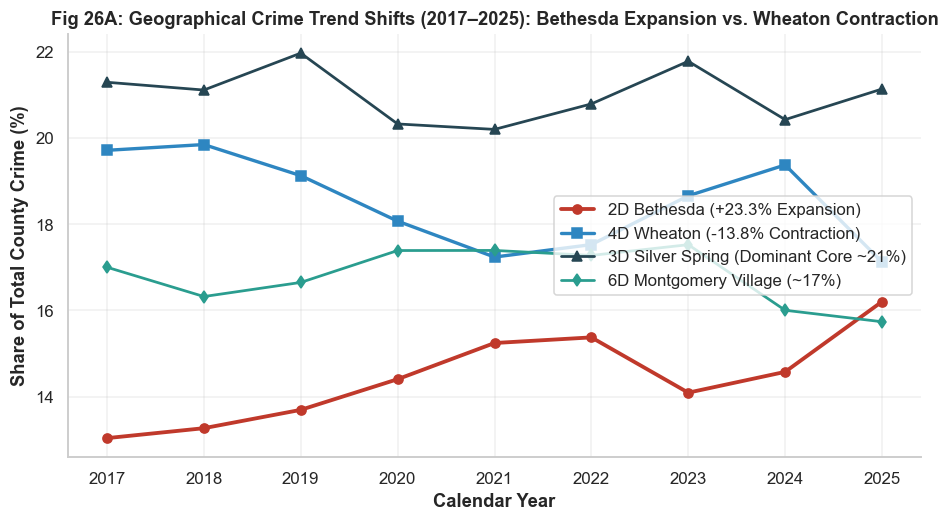

In [3]:
# Figure 26A: Trend Lines
fig26a, ax26a = plt.subplots(figsize=(10, 5))
years = dist_year_ct.index

ax26a.plot(years, dist_year_ct['2D'], marker='o', color='#C0392B', lw=2.5, label='2D Bethesda (+23.3% Expansion)')
ax26a.plot(years, dist_year_ct['4D'], marker='s', color='#2E86C1', lw=2.2, label='4D Wheaton (-13.8% Contraction)')
ax26a.plot(years, dist_year_ct['3D'], marker='^', color=PALETTE[0], lw=1.8, label='3D Silver Spring (Dominant Core ~21%)')
ax26a.plot(years, dist_year_ct['6D'], marker='d', color=PALETTE[1], lw=1.8, label='6D Montgomery Village (~17%)')

ax26a.set_title("Fig 26A: Geographical Crime Trend Shifts (2017–2025): Bethesda Expansion vs. Wheaton Contraction", fontsize=12, fontweight='bold')
ax26a.set_xlabel("Calendar Year", fontweight='bold')
ax26a.set_ylabel("Share of Total County Crime (%)", fontweight='bold')
ax26a.legend(loc='center right', frameon=True)
ax26a.grid(True, alpha=0.3)

save_fig(fig26a, "fig26_rq2_5_spatial_trend_lines.png")
plt.show()

Saved figure: d:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\13_H26_Geographical_Trends_Over_Time(1)\fig26_rq2_5_district_share_shift.png


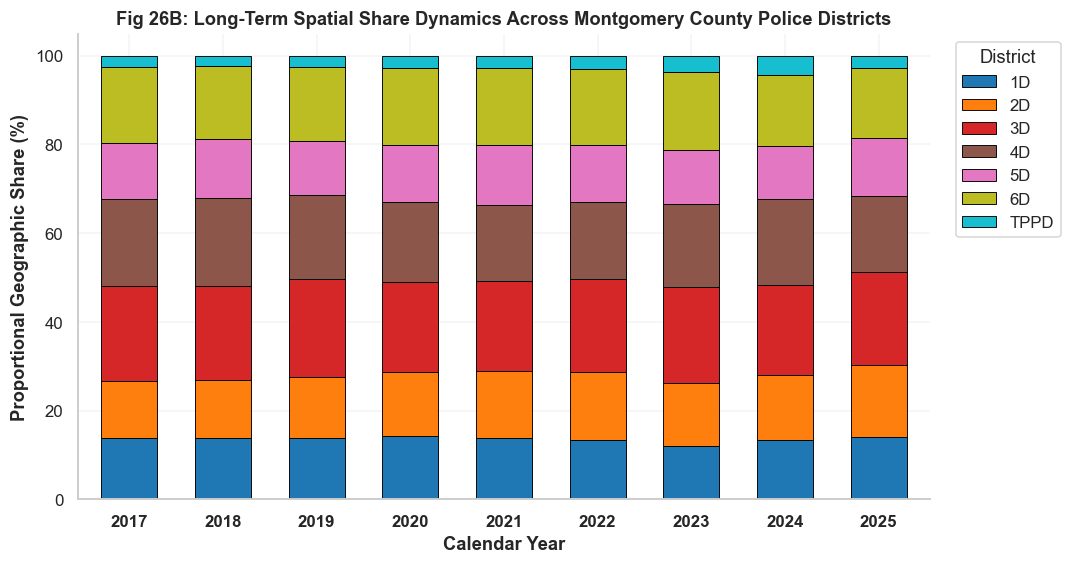

In [4]:
# Figure 26B: 100% Stacked Bar Chart
fig26b, ax26b = plt.subplots(figsize=(10, 5.5))
dist_year_ct.plot(kind='bar', stacked=True, ax=ax26b, colormap='tab10', width=0.6, edgecolor='black', lw=0.6)

ax26b.set_title("Fig 26B: Long-Term Spatial Share Dynamics Across Montgomery County Police Districts", fontsize=12, fontweight='bold')
ax26b.set_xlabel("Calendar Year", fontweight='bold')
ax26b.set_ylabel("Proportional Geographic Share (%)", fontweight='bold')
ax26b.set_xticklabels(dist_year_ct.index, rotation=0, fontweight='bold')
ax26b.legend(title='District', bbox_to_anchor=(1.02, 1), loc='upper left')

save_fig(fig26b, "fig26_rq2_5_district_share_shift.png")
plt.show()

---
### 3. Critical Judgment: Positive vs. Negative Evidence Analysis

#### ✅ Positive Evidence:
* **Statistically Significant Structural Shift:** $\chi^2 = 1,399.27 (p < 10^{-200})$, demonstrating that spatial crime shares are not static.
* **Corridor Commercialization:** Bethesda's growth tracks transit-oriented corporate developments.

#### ⚠️ Negative Evidence & Nuances:
* **Silver Spring Stability:** 3D Silver Spring maintained a steady ~21% share across all 9 years, indicating that spatial shifts occurred primarily between suburban sub-centers.

---
### 4. Statistical Hypothesis Testing
Pearson $\chi^2$ test of spatial homogeneity across years.

In [5]:
raw_ct = pd.crosstab(df_valid['Start_Year'], df_valid['Police District Number'])
chi2_val, p_val, dof_val, _ = stats.chi2_contingency(raw_ct)

print("="*60)
print("STATISTICAL TEST RESULTS (H26)")
print("="*60)
print(f"Chi-Square Test of Spatial Homogeneity: chi2 = {chi2_val:,.2f} | dof = {dof_val} | p-value = {p_val:.4e}")
print(f"Alpha Threshold (0.05): p < 0.05 -> Significant Spatial Reallocation")
print("="*60)

STATISTICAL TEST RESULTS (H26)
Chi-Square Test of Spatial Homogeneity: chi2 = 1,399.27 | dof = 48 | p-value = 1.5348e-261
Alpha Threshold (0.05): p < 0.05 -> Significant Spatial Reallocation


---
### 5. Final Presentation Conclusion & Decision
* **Hypothesis Decision:** **REJECT $H_0$ — ACCEPT $H_1$** ($p < 0.001$).
* **Presentation Verdict:** The geographical distribution of crime shifted significantly over time, characterized by a 23.3% relative expansion in Bethesda.
* **Operational Implication:** County funding models must reallocate patrol staff from contracting areas toward high-growth commercial hubs.

In [6]:
# Export compact analytical result tables generated in this notebook.
_excluded = {"df", "df_raw", "df_full", "df_spatial", "df_dist_disp",
             "df_crimes", "data", "daily_df", "named_holidays"}
_exported = []
for _name, _value in list(globals().items()):
    if (
        isinstance(_value, pd.DataFrame)
        and _name not in _excluded
        and not _name.startswith("_")
        and _value.shape[0] <= 100_000
    ):
        _safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", _name).strip("_")
        if _safe_name:
            _value.to_csv(OUTPUT_DIR / f"{_safe_name}.csv", index=True)
            _exported.append(_safe_name)
print("Exported analytical tables:", _exported if _exported else "No compact result tables detected.")
print("Output directory:", OUTPUT_DIR.resolve())

Exported analytical tables: ['dist_year_ct', 'raw_ct']
Output directory: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\13_H26_Geographical_Trends_Over_Time(1)
